In [1]:
import os
from pathlib import Path

import numpy as np
import uproot as uproot
import pandas as pd
import awkward as ak

import matplotlib.pyplot as plt
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

In [2]:
lambda_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/lambdaFransOutput.root"
frans_tdir = "FRANSProducer/fransTree"

lambda_tree = uproot.open(lambda_file)[frans_tdir]

In [10]:
branches = [
 'file_name',
 'event_id',
 'run_id',
 'subrun_id',
 'slice_id',
 'gen_index',
 'nu_pdg',
 #'nu_e0',
 #'nu_weight',
 'nu_int_mode',
 'nu_int_type',
 'nu_cc_nc',
 #'nu_target',
 #'nu_hit_nuc',
 #'nu_hit_quark',
 #'nu_w',
 #'nu_x',
 #'nu_y',
 #'nu_q_sqr',
 'gen_id',
 'gen_status_code',
 'gen_mother',
 'gen_pdg',
 'gen_mass',
 'gen_e0',
 'gen_start_x',
 'gen_start_y',
 'gen_start_z',
 'gen_p0_x',
 'gen_p0_y',
 'gen_p0_z',
 'n_protons',
 'n_neutrons',
 'n_pi0',
 'n_pip',
 'n_pim',
 'n_mup',
 'n_mum',
 'n_ep',
 'n_em',
 'n_lambda',
 'n_sigma0',
 'n_sigmap',
 'n_sigmam',
 'n_hyperon',
  'g4_id',
  'g4_mother',
  'g4_pdg',
  'g4_e0',
'g4_p0_x',
 'g4_p0_y',
 'g4_p0_z',
  'g4_process',
  'g4_end_process',
  'g4_mass',
 'true_gap',
 'has_lambda',
 'has_lambda_v',
 'is_lambda_signal',
]

In [11]:
max_entry = None

arr = lambda_tree.arrays(branches, 
                         library="ak", 
                         cut = 'is_lambda_signal==1',
                         entry_stop=max_entry)

In [12]:
len(arr)

72643

# Look for pion and proton decayed from Lambda

In [13]:
# tests to be included in a function

lambda_mask = arr.g4_pdg == 3122

In [14]:
lambda_ids = ak.flatten(arr.g4_id[lambda_mask], axis=1)

In [15]:
lambda_dau_mask = arr.g4_mother == lambda_ids

In [16]:
pion_mask = (lambda_dau_mask) & (arr.g4_pdg == -211)
proton_mask = (lambda_dau_mask) & (arr.g4_pdg == 2212)

In [24]:
pion_momentum = np.sqrt(ak.flatten((arr.g4_p0_x[pion_mask]**2 + arr.g4_p0_y[pion_mask]**2 + arr.g4_p0_z[pion_mask]**2), axis=1)) * 1000
proton_momentum = np.sqrt(ak.flatten((arr.g4_p0_x[proton_mask]**2 + arr.g4_p0_y[proton_mask]**2 + arr.g4_p0_z[proton_mask]**2), axis=1)) * 1000

In [25]:
pion_energy = ak.flatten(arr.g4_e0[pion_mask], axis=1) * 1000
proton_energy = ak.flatten(arr.g4_e0[proton_mask], axis=1) * 1000

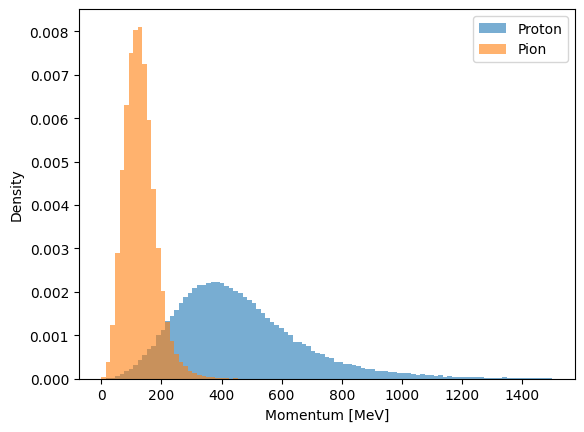

In [32]:
proton_mass = 938 # Mev
pion_mass = 139.57 # Mev

pion_mom = np.sqrt(pion_energy**2 - pion_mass**2)
proton_mom = np.sqrt(proton_energy**2 - proton_mass**2)

bins = np.linspace(0,1500,100)

plt.hist(proton_mom, bins=bins, label='Proton', alpha=0.6, density=True)
plt.hist(pion_mom, bins=bins, label='Pion', alpha=0.6, density=True)
plt.xlabel('Momentum [MeV]')
plt.ylabel('Density')
plt.legend()